# Real-Time Air Quality Forecasting and Spike Detection for Karachi
**Team:** Naresh Kumar (25K-2501) and Syed Zaid Khalid (25K-2522)

Run the cells from top to bottom.

| Part | Phases | What it does |
|---|---|---|
| 1 | 2 and 3 | Data quality report, cleaning, features, and exploration (EDA) |
| 2 | 4 and 5 | SARIMA forecasting (with residual and confidence-band checks) and spike detection |
| 3 | 6 | Baseline models, comparison, and a significance test |
| 4 | extra | Checks against real-world data (ground sensors, Open-Meteo's own forecast) |

**Before you start:** run `backfill.py` once to create `karachi_aq_history.csv` (and `refresh.py` any time you want newer data).
This notebook creates: `data_quality_report.csv`, `clean_data.csv`, `sarima_results.csv`, `band_coverage.csv`, `spike_flags.csv`,
`model_comparison.csv`, `significance_results.csv`, `sensitivity_results.csv`, `model.pkl`.

The full run takes a few minutes, mostly in the SARIMA steps.

## Settings (used in several parts)

In [1]:
import numpy as np

# forecast from a new starting point every 3 hours.
# More starting points = more reliable error numbers. Parts 2 and 3 both use this number.
origin_step = 3

# when SARIMA makes a forecast it looks at the last 14 days of history (this keeps it fast)
history_window = 24 * 14

# fixed random seed, so the results are the same every time you run it
np.random.seed(42)

# Part 1: Phases 2 and 3 - Cleaning, features and exploration
Uses `karachi_aq_history.csv` made by `backfill.py`.


## Phase 2: Cleaning and features

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Step 1: Load the data and check it

In [3]:
table = pd.read_csv("karachi_aq_history.csv")

print("Rows and columns:", table.shape)
print(table.head())
print(table.info())

Rows and columns: (2227, 8)
                  time  pm2_5  pm10  nitrogen_dioxide  ozone  temperature_2m  \
0  2026-08-13 00:00:00   19.4  38.3              12.8   40.0             NaN   
1  2026-08-13 01:00:00   20.8  41.8              11.2   41.0             NaN   
2  2026-08-13 02:00:00   19.3  38.5               9.8   42.0             NaN   
3  2026-08-13 03:00:00   18.3  36.9               8.6   42.0             NaN   
4  2026-08-13 04:00:00   17.2  34.5               7.6   42.0             NaN   

   relative_humidity_2m  wind_speed_10m  
0                   NaN             NaN  
1                   NaN             NaN  
2                   NaN             NaN  
3                   NaN             NaN  
4                   NaN             NaN  
<class 'pandas.DataFrame'>
RangeIndex: 2227 entries, 0 to 2226
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   time                  2227 non-null  

### Data quality report
A quick check for common data problems before we clean anything. The numbers are saved in `data_quality_report.csv`.

In [4]:
# 1. missing values
missing_total = table.isna().sum().sum()

# 2. duplicate timestamps
duplicate_times = table["time"].duplicated().sum()

# 3. gaps in time (a step that is not exactly 1 hour)
sorted_times = pd.to_datetime(table["time"]).drop_duplicates().sort_values()
steps = sorted_times.diff().dropna()
gap_count = (steps != pd.Timedelta(hours=1)).sum()

# 4. outliers in PM2.5 (above Q3 + 1.5 x IQR) and impossible values (below 0)
pm_values = table["pm2_5"].dropna()
q1 = pm_values.quantile(0.25)
q3 = pm_values.quantile(0.75)
upper_limit = q3 + 1.5 * (q3 - q1)
outlier_count = (pm_values > upper_limit).sum()
negative_count = (pm_values < 0).sum()

# 5. flat stretches (the same PM2.5 value 6 hours in a row can mean a stuck sensor or model)
same_as_before = (pm_values == pm_values.shift(1))
flat_count = same_as_before.rolling(5).sum().ge(5).sum()

report_rows = [
    {"check": "Rows", "result": len(table)},
    {"check": "First hour", "result": str(sorted_times.min())},
    {"check": "Last hour", "result": str(sorted_times.max())},
    {"check": "Missing values (all columns)", "result": int(missing_total)},
    {"check": "Duplicate timestamps", "result": int(duplicate_times)},
    {"check": "Time gaps (not exactly 1 hour)", "result": int(gap_count)},
    {"check": "PM2.5 outliers (above " + str(round(upper_limit, 1)) + ")", "result": int(outlier_count)},
    {"check": "PM2.5 below zero", "result": int(negative_count)},
    {"check": "Flat stretches (6 equal values in a row)", "result": int(flat_count)},
]

report = pd.DataFrame(report_rows)
print(report)
report.to_csv("data_quality_report.csv", index=False)

                                      check               result
0                                      Rows                 2227
1                                First hour  2026-08-13 00:00:00
2                                 Last hour  2026-11-13 18:00:00
3              Missing values (all columns)                 2031
4                      Duplicate timestamps                    0
5            Time gaps (not exactly 1 hour)                    0
6               PM2.5 outliers (above 48.0)                   89
7                          PM2.5 below zero                    0
8  Flat stretches (6 equal values in a row)                    0


**Interpretation:** (which problems did we find? the next steps remove duplicates and fill gaps; outliers are kept because real pollution spikes are the thing we want to study.)

### Step 2: Fix the time column and remove duplicates

In [5]:
# make the time column a real date and time
table["time"] = pd.to_datetime(table["time"])

# put rows in time order
table = table.sort_values("time")

# remove rows that have the same time twice
rows_before = len(table)
table = table.drop_duplicates(subset="time")
rows_after = len(table)

print("Duplicate rows removed:", rows_before - rows_after)

Duplicate rows removed: 0


### Step 3: Fill missing values

In [6]:
# how many missing values in each column
print(table.isna().sum())

time                      0
pm2_5                     0
pm10                      0
nitrogen_dioxide          0
ozone                     0
temperature_2m          677
relative_humidity_2m    677
wind_speed_10m          677
dtype: int64


In [7]:
# fill small gaps using the values before and after
table = table.set_index("time")
table = table.interpolate(method="time")
table = table.reset_index()

# check again, it should now be 0 (or very small)
print(table.isna().sum())

time                      0
pm2_5                     0
pm10                      0
nitrogen_dioxide          0
ozone                     0
temperature_2m          677
relative_humidity_2m    677
wind_speed_10m          677
dtype: int64


### Step 4: Add time columns

In [8]:
table["hour"] = table["time"].dt.hour
table["day_of_week"] = table["time"].dt.dayofweek    # 0 = Monday, 6 = Sunday
table["month"] = table["time"].dt.month

# weekend = Saturday or Sunday
table["is_weekend"] = 0
table.loc[table["day_of_week"] >= 5, "is_weekend"] = 1

# night = 10 PM to 5 AM
table["is_night"] = 0
table.loc[(table["hour"] >= 22) | (table["hour"] <= 5), "is_night"] = 1

# rush hours = 7 to 10 AM and 5 to 8 PM
table["is_rush_hour"] = 0
table.loc[(table["hour"] >= 7) & (table["hour"] <= 10), "is_rush_hour"] = 1
table.loc[(table["hour"] >= 17) & (table["hour"] <= 20), "is_rush_hour"] = 1

print(table[["time", "hour", "day_of_week", "is_weekend", "is_night", "is_rush_hour"]].head())

                 time  hour  day_of_week  is_weekend  is_night  is_rush_hour
0 2026-08-13 00:00:00     0            3           0         1             0
1 2026-08-13 01:00:00     1            3           0         1             0
2 2026-08-13 02:00:00     2            3           0         1             0
3 2026-08-13 03:00:00     3            3           0         1             0
4 2026-08-13 04:00:00     4            3           0         1             0


### Step 5: Add past-value columns (lags) and rolling averages
Each row only uses values from the PAST, so the model never sees the future.

In [9]:
# PM2.5 value 1, 3 and 24 hours ago
table["pm2_5_lag1"] = table["pm2_5"].shift(1)
table["pm2_5_lag3"] = table["pm2_5"].shift(3)
table["pm2_5_lag24"] = table["pm2_5"].shift(24)

# average of the last 3 and last 24 hours (not including the current hour)
past_pm = table["pm2_5"].shift(1)
table["pm2_5_avg3"] = past_pm.rolling(3).mean()
table["pm2_5_avg24"] = past_pm.rolling(24).mean()

# the first 24 rows have no past values, so remove them
table = table.dropna()

print("Rows and columns after cleaning:", table.shape)
print(table.head())

Rows and columns after cleaning: (1550, 19)
                   time  pm2_5  pm10  nitrogen_dioxide  ozone  temperature_2m  \
677 2026-09-10 05:00:00   16.6  39.8              16.6   24.0            25.9   
678 2026-09-10 06:00:00   17.2  40.9              16.6   25.0            25.8   
679 2026-09-10 07:00:00   19.8  48.8              16.5   28.0            26.2   
680 2026-09-10 08:00:00   19.6  53.6              15.5   34.0            27.1   
681 2026-09-10 09:00:00   20.0  59.3              12.9   48.0            28.2   

     relative_humidity_2m  wind_speed_10m  hour  day_of_week  month  \
677                  91.0             4.6     5            3      9   
678                  90.0             4.6     6            3      9   
679                  87.0             4.8     7            3      9   
680                  80.0             5.5     8            3      9   
681                  74.0             6.5     9            3      9   

     is_weekend  is_night  is_rush_hour  p

### Step 6: Save the clean table

In [10]:
table.to_csv("clean_data.csv", index=False)
print("Saved clean_data.csv")

Saved clean_data.csv


## Phase 3: Exploration (EDA)

### Summary numbers

In [11]:
print(table[["pm2_5", "pm10", "nitrogen_dioxide", "ozone", "temperature_2m", "relative_humidity_2m", "wind_speed_10m"]].describe())

             pm2_5         pm10  nitrogen_dioxide        ozone  \
count  1550.000000  1550.000000       1550.000000  1550.000000   
mean     28.101419    52.796516         22.106000    68.188387   
std      10.439671    27.650772         17.770872    43.358825   
min       8.600000    12.900000          2.200000     0.000000   
25%      21.000000    34.500000          8.500000    36.000000   
50%      26.400000    46.900000         16.500000    56.000000   
75%      32.700000    63.600000         31.700000    93.000000   
max      75.000000   241.200000        114.000000   191.000000   

       temperature_2m  relative_humidity_2m  wind_speed_10m  
count     1550.000000           1550.000000     1550.000000  
mean        28.645677             66.333548        9.510516  
std          3.118769             20.852591        3.716908  
min         20.100000             10.000000        0.300000  
25%         26.500000             54.000000        6.900000  
50%         28.000000            

### Chart 1: PM2.5 over time

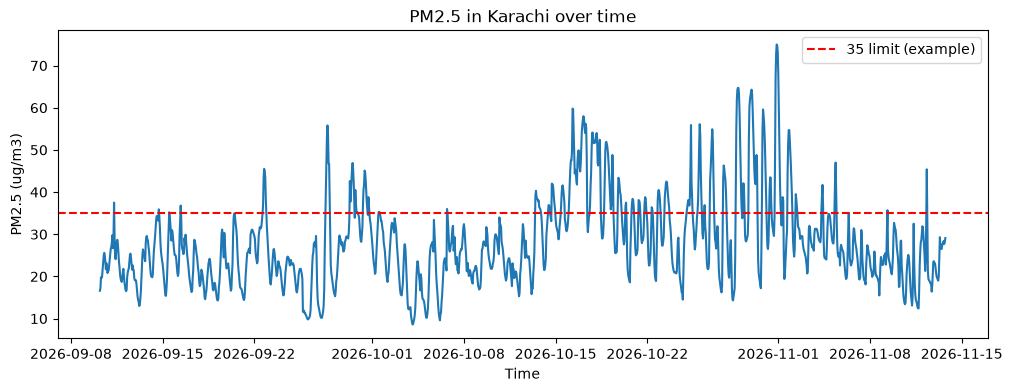

In [12]:
plt.figure(figsize=(12, 4))
plt.plot(table["time"], table["pm2_5"])
plt.axhline(35, color="red", linestyle="--", label="35 limit (example)")
plt.title("PM2.5 in Karachi over time")
plt.xlabel("Time")
plt.ylabel("PM2.5 (ug/m3)")
plt.legend()
plt.show()

**Interpretation:** (write 2 or 3 sentences after you see the chart: is there a trend? are there big spikes?)

### Chart 2: Average PM2.5 by hour of day

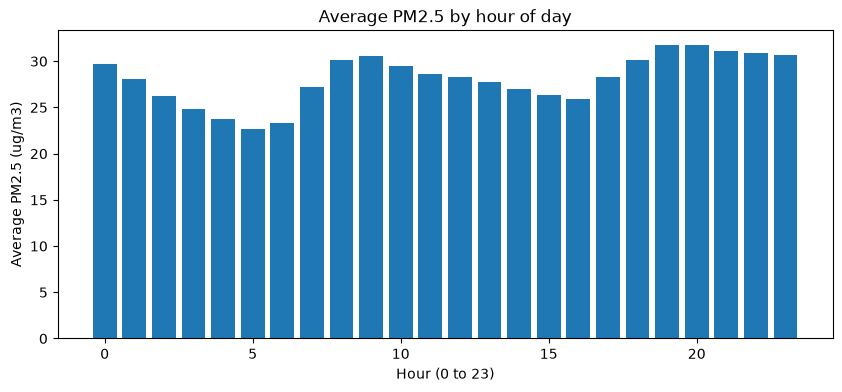

In [13]:
hour_average = table.groupby("hour")["pm2_5"].mean()

plt.figure(figsize=(10, 4))
plt.bar(hour_average.index, hour_average.values)
plt.title("Average PM2.5 by hour of day")
plt.xlabel("Hour (0 to 23)")
plt.ylabel("Average PM2.5 (ug/m3)")
plt.show()

**Interpretation:** (which hours are highest and lowest? does it match rush hours?)

### Chart 3: Average PM2.5 by day of week

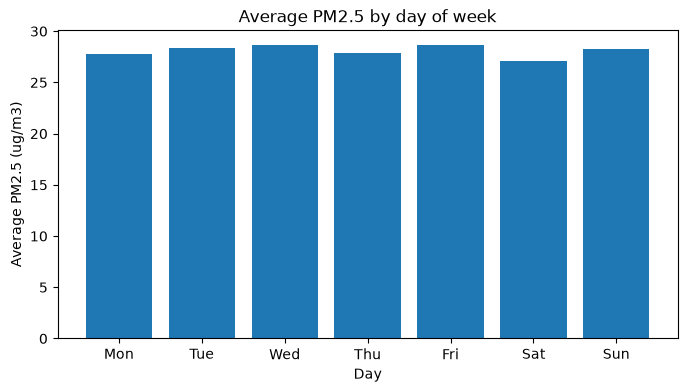

In [14]:
day_average = table.groupby("day_of_week")["pm2_5"].mean()
day_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

plt.figure(figsize=(8, 4))
plt.bar(day_names, day_average.values)
plt.title("Average PM2.5 by day of week")
plt.xlabel("Day")
plt.ylabel("Average PM2.5 (ug/m3)")
plt.show()

**Interpretation:** (is the weekend different from weekdays?)

### Chart 4: PM2.5 versus wind speed and humidity

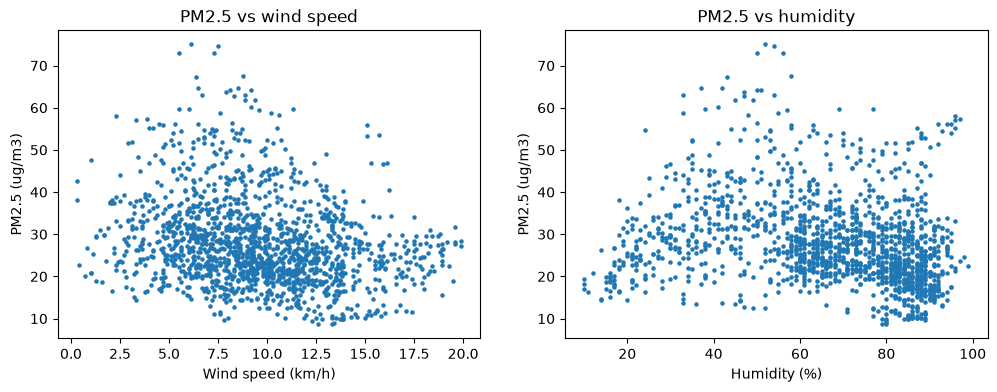

In [15]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.scatter(table["wind_speed_10m"], table["pm2_5"], s=5)
plt.title("PM2.5 vs wind speed")
plt.xlabel("Wind speed (km/h)")
plt.ylabel("PM2.5 (ug/m3)")

plt.subplot(1, 2, 2)
plt.scatter(table["relative_humidity_2m"], table["pm2_5"], s=5)
plt.title("PM2.5 vs humidity")
plt.xlabel("Humidity (%)")
plt.ylabel("PM2.5 (ug/m3)")

plt.show()

**Interpretation:** (does more wind mean less PM2.5? what about humidity?)

### Chart 5: Correlation heatmap

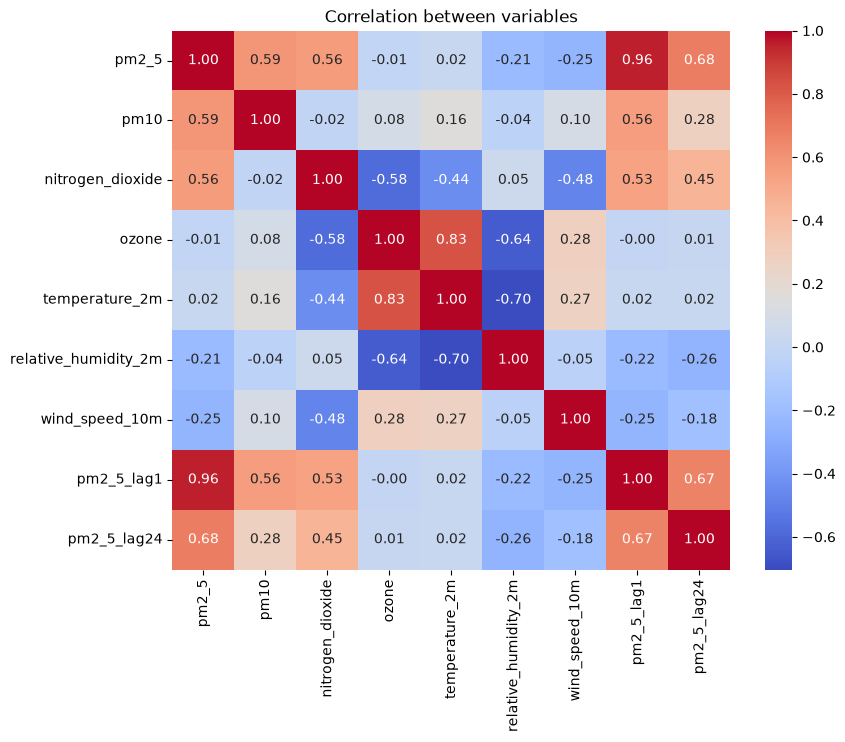

In [16]:
small_table = table[["pm2_5", "pm10", "nitrogen_dioxide", "ozone", "temperature_2m", "relative_humidity_2m", "wind_speed_10m", "pm2_5_lag1", "pm2_5_lag24"]]

plt.figure(figsize=(9, 7))
sns.heatmap(small_table.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation between variables")
plt.show()

**Interpretation:** (which variables are most related to PM2.5? is lag1 very high? what does that mean for forecasting?)

## Notes for the report
- Data comes from the CAMS model through Open-Meteo, not from ground sensors.
- The 35 line on the charts is an example limit. Confirm the exact standard you cite.
- Next: Phase 4 (SARIMA) will use `clean_data.csv`.

# Part 2: Phases 4 and 5 - SARIMA forecasting and spike detection
Uses `clean_data.csv` made in Part 1.
Install once if needed: `pip install statsmodels scikit-learn`


## Phase 4: SARIMA forecasting

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

### Step 1: Load the clean data and split it by time

In [18]:
table = pd.read_csv("clean_data.csv")
table["time"] = pd.to_datetime(table["time"])

# only the PM2.5 numbers, in time order
pm = table["pm2_5"].reset_index(drop=True)

# first 80% of hours = training, last 20% = testing (no shuffling!)
test_start = int(len(pm) * 0.8)
train = pm[:test_start]
test = pm[test_start:]

print("Training hours:", len(train))
print("Testing hours:", len(test))

Training hours: 1240
Testing hours: 310


### Step 2: Fit the SARIMA model
`order=(1,0,1)` means: use the last hour (AR) and the last error (MA).
`seasonal_order=(1,0,1,24)` means: the same idea, but for the 24-hour daily cycle.
This step can take about a minute.

In [19]:
# fit on the last 90 days before the test period (the daily cycle is learned quickly, and this keeps it fast)
fit_data = train[-24 * 90:]

model = SARIMAX(fit_data, order=(1, 0, 1), seasonal_order=(1, 0, 1, 24))
results = model.fit(disp=False)

print(results.summary())

                                     SARIMAX Results                                      
Dep. Variable:                              pm2_5   No. Observations:                 1240
Model:             SARIMAX(1, 0, 1)x(1, 0, 1, 24)   Log Likelihood               -2674.112
Date:                            Sun, 15 Nov 2026   AIC                           5358.224
Time:                                    12:29:41   BIC                           5383.838
Sample:                                         0   HQIC                          5367.857
                                           - 1240                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.9553      0.007    131.113      0.000       0.941       0.970
ma.L1          0.4130      0.018   

### Step 2b: Residual check
Residuals = real PM2.5 minus what the fitted model expected. If the model captured the daily pattern,
the residuals should look like random noise with no repeating pattern left.

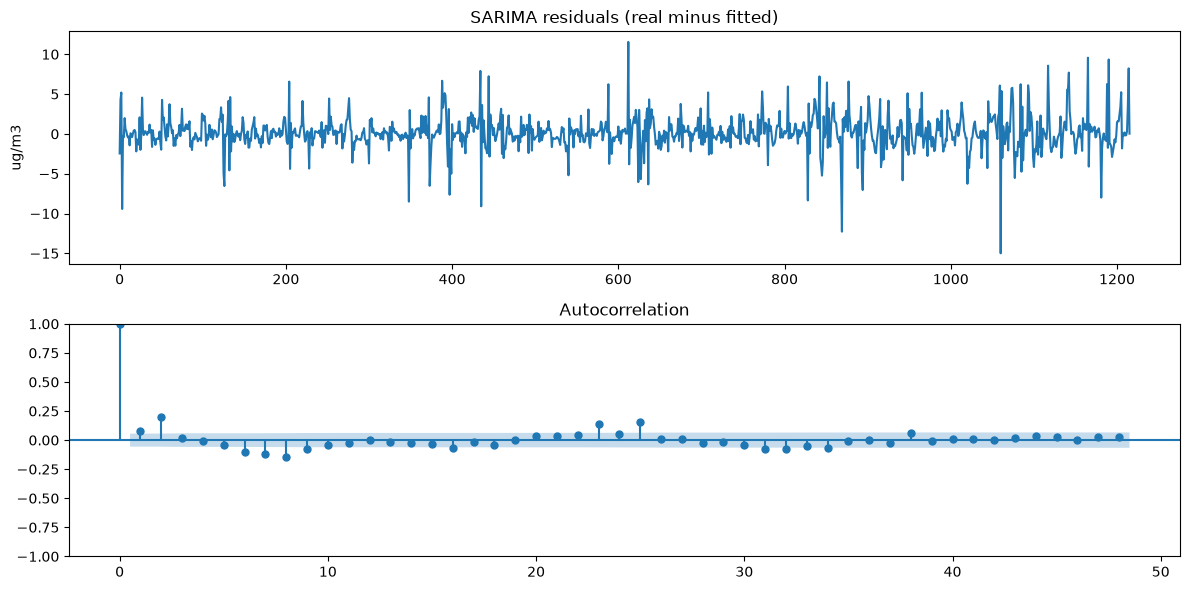

       lb_stat     lb_pvalue
24  168.662575  1.046998e-23


In [20]:
residuals = results.resid[24:]       # skip the first day (the model is still warming up)

plt.figure(figsize=(12, 6))

plt.subplot(2, 1, 1)
plt.plot(residuals.values)
plt.title("SARIMA residuals (real minus fitted)")
plt.ylabel("ug/m3")

plt.subplot(2, 1, 2)
plot_acf(residuals, lags=48, ax=plt.gca())

plt.tight_layout()
plt.show()

# Ljung-Box test: a small p-value (below 0.05) means some pattern is still left in the residuals
ljung = acorr_ljungbox(residuals, lags=[24])
print(ljung)

**Interpretation:** (do the bars in the lower chart stay mostly inside the blue band? is the Ljung-Box p-value above 0.05?
Some leftover pattern is common with simple models. If you see it, say so honestly in the report.)

### Step 3: Forecast the next 72 hours and draw it with the confidence band

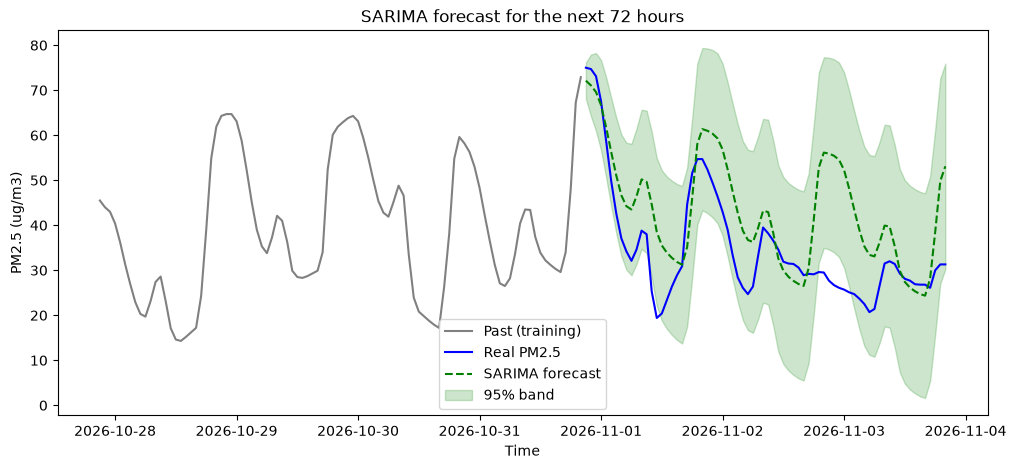

In [21]:
forecast = results.get_forecast(steps=72)
forecast_values = forecast.predicted_mean
band = forecast.conf_int()
lower = band.iloc[:, 0]
upper = band.iloc[:, 1]

# real values for the same 72 hours
real_values = test[:72]

# time labels for the chart
past_times = table["time"][test_start - 96 : test_start]
future_times = table["time"][test_start : test_start + 72]
past_values = train[test_start - 96 : test_start]

plt.figure(figsize=(12, 5))
plt.plot(past_times, past_values, color="gray", label="Past (training)")
plt.plot(future_times, real_values.values, color="blue", label="Real PM2.5")
plt.plot(future_times, forecast_values.values, color="green", linestyle="--", label="SARIMA forecast")
plt.fill_between(future_times, lower.values, upper.values, color="green", alpha=0.2, label="95% band")
plt.title("SARIMA forecast for the next 72 hours")
plt.xlabel("Time")
plt.ylabel("PM2.5 (ug/m3)")
plt.legend()
plt.show()

**Interpretation:** (does the forecast follow the daily up and down? does the band get wider further away?)

### Step 4: Measure the error at +1, +6, +24, +48 and +72 hours
We repeat the forecast from many starting points in the test period (every `origin_step` hours, set at the top of the notebook),
so each horizon gets several errors, not just one.
We also test the naive baseline: the value at the same hour on the last known day.

In [22]:
horizons = [1, 6, 24, 48, 72]

# empty lists to collect errors
sarima_errors = {}
naive_errors = {}
band_hits = {}
for h in horizons:
    sarima_errors[h] = []
    naive_errors[h] = []
    band_hits[h] = []

origin = test_start
while origin + 72 <= len(pm):

    # everything we know up to this moment
    # the last 14 days we know up to this moment
    history = pm[max(0, origin - history_window) : origin]

    # reuse the learned model on the new history (no refit, so it is fast)
    new_results = results.apply(history, refit=False)
    new_forecast_all = new_results.get_forecast(steps=72)
    new_forecast = new_forecast_all.predicted_mean
    new_band = new_forecast_all.conf_int()

    for h in horizons:
        target_position = origin + h - 1
        real = pm[target_position]

        # SARIMA error
        sarima_guess = new_forecast.iloc[h - 1]
        sarima_errors[h].append(real - sarima_guess)

        # was the real value inside the 95% band?
        band_low = new_band.iloc[h - 1, 0]
        band_high = new_band.iloc[h - 1, 1]
        if band_low <= real <= band_high:
            band_hits[h].append(1)
        else:
            band_hits[h].append(0)

        # naive guess: same hour, on the last day we already know
        days_back = (h + 23) // 24
        naive_guess = pm[target_position - 24 * days_back]
        naive_errors[h].append(real - naive_guess)

    # move the starting point forward by 24 hours
    origin = origin + origin_step

print("Number of starting points used:", len(sarima_errors[1]))

Number of starting points used: 80


In [23]:
rows = []
for h in horizons:
    s_errors = np.array(sarima_errors[h])
    n_errors = np.array(naive_errors[h])

    row = {
        "horizon_hours": h,
        "SARIMA_RMSE": np.sqrt(np.mean(s_errors ** 2)),
        "SARIMA_MAE": np.mean(np.abs(s_errors)),
        "Naive_RMSE": np.sqrt(np.mean(n_errors ** 2)),
        "Naive_MAE": np.mean(np.abs(n_errors)),
    }
    rows.append(row)

results_table = pd.DataFrame(rows)
results_table = results_table.round(2)
print(results_table)

results_table.to_csv("sarima_results.csv", index=False)

   horizon_hours  SARIMA_RMSE  SARIMA_MAE  Naive_RMSE  Naive_MAE
0              1         2.24        1.51        8.22       5.85
1              6         7.96        5.79        8.27       6.12
2             24         6.18        4.59        7.83       5.72
3             48         7.36        5.12       10.39       6.78
4             72         6.62        4.97        9.70       6.58


### Step 4b: Is the 95% band honest?
A good 95% band should contain the real value about 95% of the time. Much lower means the model is overconfident.

   horizon_hours  percent_inside_95_band
0              1                    95.0
1              6                    91.2
2             24                    97.5
3             48                    97.5
4             72                   100.0


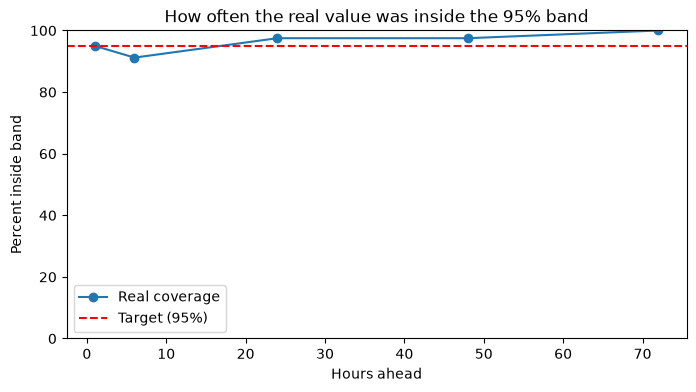

In [24]:
coverage_rows = []
for h in horizons:
    hits = np.array(band_hits[h])
    coverage_rows.append({"horizon_hours": h, "percent_inside_95_band": round(hits.mean() * 100, 1)})

coverage_table = pd.DataFrame(coverage_rows)
print(coverage_table)
coverage_table.to_csv("band_coverage.csv", index=False)

plt.figure(figsize=(8, 4))
plt.plot(coverage_table["horizon_hours"], coverage_table["percent_inside_95_band"], marker="o", label="Real coverage")
plt.axhline(95, color="red", linestyle="--", label="Target (95%)")
plt.title("How often the real value was inside the 95% band")
plt.xlabel("Hours ahead")
plt.ylabel("Percent inside band")
plt.ylim(0, 100)
plt.legend()
plt.show()

**Interpretation:** (is coverage close to 95%? at which horizon does the band become too narrow or too wide?)

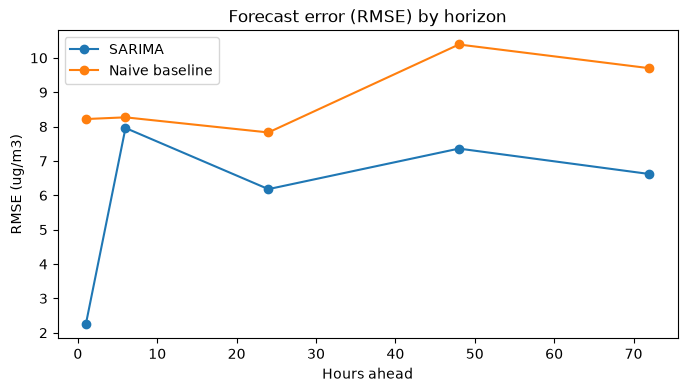

In [25]:
plt.figure(figsize=(8, 4))
plt.plot(results_table["horizon_hours"], results_table["SARIMA_RMSE"], marker="o", label="SARIMA")
plt.plot(results_table["horizon_hours"], results_table["Naive_RMSE"], marker="o", label="Naive baseline")
plt.title("Forecast error (RMSE) by horizon")
plt.xlabel("Hours ahead")
plt.ylabel("RMSE (ug/m3)")
plt.legend()
plt.show()

**Interpretation:** (does the error grow with the horizon? does SARIMA beat the naive baseline at every horizon?
Remember: each horizon uses only a few starting points, so say the results are approximate.)

## Phase 5: Spike detection

In [26]:
from sklearn.ensemble import IsolationForest
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler

### Step 1: Prepare the columns
We add one helpful column: how far PM2.5 is from its normal level at that hour of the day.
The normal level is learned from the training hours only.

In [27]:
train_table = table[:test_start]
test_table = table[test_start:]

# normal PM2.5 for each hour of day (from training hours only)
hour_normal = train_table.groupby("hour")["pm2_5"].mean()
table["hour_average"] = table["hour"].map(hour_normal)
table["pm_vs_hour"] = table["pm2_5"] - table["hour_average"]

# the columns the detectors will look at
features = ["pm2_5", "pm10", "wind_speed_10m", "relative_humidity_2m", "pm_vs_hour"]

train_table = table[:test_start]
test_table = table[test_start:]

### Step 2: Isolation Forest
It learns from the training hours, then judges every hour.
`contamination=0.02` means we expect about 2% of hours to be unusual.

In [28]:
iso_model = IsolationForest(n_estimators=200, contamination=0.02, random_state=42)
iso_model.fit(train_table[features])

answer = iso_model.predict(table[features])      # -1 = unusual, 1 = normal

table["if_spike"] = 0
table.loc[answer == -1, "if_spike"] = 1

test_table = table[test_start:]
print("Hours flagged by Isolation Forest in the test period:", test_table["if_spike"].sum(), "out of", len(test_table))

Hours flagged by Isolation Forest in the test period: 4 out of 310


### Step 3: A simple rule to compare with (PM2.5 above the 95th percentile of training)

In [29]:
limit = train_table["pm2_5"].quantile(0.95)
print("Rule limit (ug/m3):", round(limit, 1))

table["rule_spike"] = 0
table.loc[table["pm2_5"] > limit, "rule_spike"] = 1

test_table = table[test_start:]

both = len(test_table[(test_table["if_spike"] == 1) & (test_table["rule_spike"] == 1)])
only_if = len(test_table[(test_table["if_spike"] == 1) & (test_table["rule_spike"] == 0)])
only_rule = len(test_table[(test_table["if_spike"] == 0) & (test_table["rule_spike"] == 1)])

print("Flagged by both:", both)
print("Flagged only by Isolation Forest:", only_if)
print("Flagged only by the simple rule:", only_rule)

Rule limit (ug/m3): 50.4
Flagged by both: 4
Flagged only by Isolation Forest: 0
Flagged only by the simple rule: 5


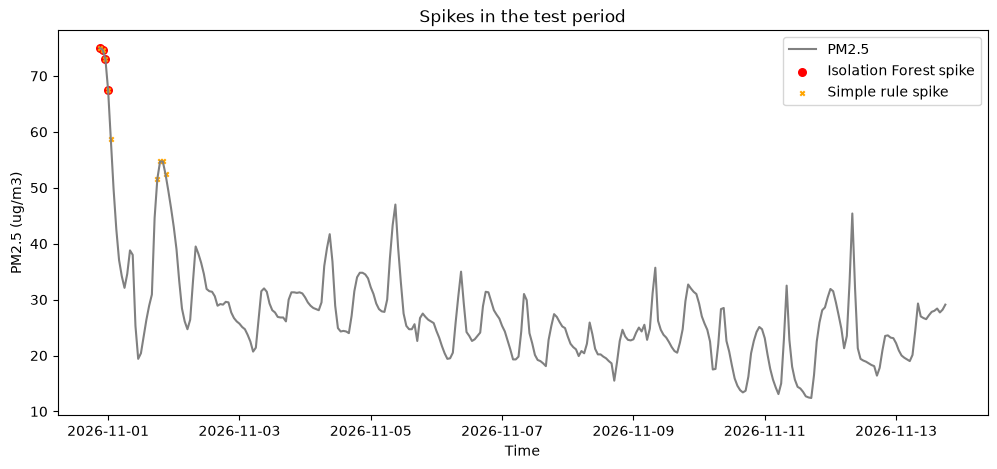

In [30]:
plt.figure(figsize=(12, 5))
plt.plot(test_table["time"], test_table["pm2_5"], color="gray", label="PM2.5")

if_points = test_table[test_table["if_spike"] == 1]
plt.scatter(if_points["time"], if_points["pm2_5"], color="red", s=30, label="Isolation Forest spike")

rule_points = test_table[test_table["rule_spike"] == 1]
plt.scatter(rule_points["time"], rule_points["pm2_5"], color="orange", s=10, marker="x", label="Simple rule spike")

plt.title("Spikes in the test period")
plt.xlabel("Time")
plt.ylabel("PM2.5 (ug/m3)")
plt.legend()
plt.show()

**Interpretation:** (which spikes did only Isolation Forest find? are they unusual for that hour even if not very high?
which ones did only the rule find?)

### Step 4 (optional): DBSCAN, a second opinion
First we scale the columns so they have the same size. Then DBSCAN marks hours that are far from the crowd as noise (label -1).
`eps` controls how far counts as "close". Try different values and pick one that flags a small share of hours.

In [31]:
scaler = StandardScaler()
scaler.fit(train_table[features])
scaled_all = scaler.transform(table[features])

# try a few eps values
for eps_value in [0.5, 1.0, 1.5, 2.0, 2.5]:
    labels = DBSCAN(eps=eps_value, min_samples=10).fit_predict(scaled_all)
    noise_count = (labels == -1).sum()
    print("eps =", eps_value, "-> hours marked unusual:", noise_count, "out of", len(labels))

eps = 0.5 -> hours marked unusual: 633 out of 1550
eps = 1.0 -> hours marked unusual: 25 out of 1550
eps = 1.5 -> hours marked unusual: 4 out of 1550
eps = 2.0 -> hours marked unusual: 0 out of 1550
eps = 2.5 -> hours marked unusual: 0 out of 1550


In [32]:
# choose your eps from the list above
chosen_eps = 1.5

labels = DBSCAN(eps=chosen_eps, min_samples=10).fit_predict(scaled_all)

table["db_spike"] = 0
table.loc[labels == -1, "db_spike"] = 1

test_table = table[test_start:]

both = len(test_table[(test_table["if_spike"] == 1) & (test_table["db_spike"] == 1)])
only_if = len(test_table[(test_table["if_spike"] == 1) & (test_table["db_spike"] == 0)])
only_db = len(test_table[(test_table["if_spike"] == 0) & (test_table["db_spike"] == 1)])

print("Flagged by both Isolation Forest and DBSCAN:", both)
print("Flagged only by Isolation Forest:", only_if)
print("Flagged only by DBSCAN:", only_db)

Flagged by both Isolation Forest and DBSCAN: 0
Flagged only by Isolation Forest: 4
Flagged only by DBSCAN: 0


**Interpretation:** (do the two methods agree? hours both flag are the most trustworthy spikes.)

### Save the flags

In [33]:
table[["time", "pm2_5", "if_spike", "rule_spike", "db_spike"]].to_csv("spike_flags.csv", index=False)
print("Saved spike_flags.csv")

Saved spike_flags.csv


## Notes for the report
- SARIMA was fitted once on the training hours and re-used (without refitting) from many starting points in the test period.
- There are no true "spike" labels, so spikes are compared against a simple rule and between methods, not scored for accuracy.
- Next: Phase 6 adds the baselines (Linear Regression, Random Forest, Gradient Boosting) once they are taught.

# Part 3: Phase 6 - Baseline models and comparison
Uses `clean_data.csv` (Part 1) and `sarima_results.csv` (Part 2).

**Course rule:** use Linear Regression and Random Forest only after they are taught, and Gradient Boosting only after weeks 11-12.
Set `use_gradient_boosting = False` below until your professor has taught it.


In [34]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, RandomForestClassifier
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, roc_auc_score

# change to False until Gradient Boosting is taught in class
use_gradient_boosting = True

## Step 1: Load the data and choose the columns

In [35]:
table = pd.read_csv("clean_data.csv")
table["time"] = pd.to_datetime(table["time"])

# same split as Phase 4: first 80% training, last 20% testing
test_start = int(len(table) * 0.8)

all_features = [
    "pm2_5", "pm10", "nitrogen_dioxide", "ozone",
    "temperature_2m", "relative_humidity_2m", "wind_speed_10m",
    "hour", "day_of_week", "is_weekend", "is_night", "is_rush_hour",
    "pm2_5_lag1", "pm2_5_lag3", "pm2_5_lag24", "pm2_5_avg3", "pm2_5_avg24",
]

weather_features = ["temperature_2m", "relative_humidity_2m", "wind_speed_10m"]

horizons = [1, 6, 24, 48, 72]
print("Rows:", len(table), " Test starts at row:", test_start)

Rows: 1550  Test starts at row: 1240


## Step 2: A helper that builds training and testing data for one horizon
For a horizon of h hours, each row says: "using what we know NOW, what will PM2.5 be h hours later?"
- Training rows: their target must still be inside the training period (no peeking at the test period).
- Test rows: the same starting points that SARIMA used (every `origin_step` hours, the same number as in Part 2), so the comparison is fair.

In [36]:
def make_data(h, feature_list, first_train_row=0):
    data = table.copy()

    # the hour of day we are trying to predict
    data["target_hour"] = (data["hour"] + h) % 24

    # the answer: PM2.5 h hours later
    data["target"] = data["pm2_5"].shift(-h)

    columns = feature_list + ["target_hour"]

    train_rows = list(range(first_train_row, test_start - h))
    test_rows = list(range(test_start - 1, len(table) - 72, origin_step))

    x_train = data.loc[train_rows, columns]
    y_train = data.loc[train_rows, "target"]
    x_test = data.loc[test_rows, columns]
    y_test = data.loc[test_rows, "target"]

    return x_train, y_train, x_test, y_test


def get_errors(real, guess):
    errors = np.array(real) - np.array(guess)
    rmse = np.sqrt(np.mean(errors ** 2))
    mae = np.mean(np.abs(errors))
    return rmse, mae

## Step 3: Train the models for every horizon
Linear Regression works best when columns have a similar size, so we scale them for that model only.

In [37]:
rows = []
ml_errors = {}      # we keep every error so we can test the differences later

for h in horizons:
    x_train, y_train, x_test, y_test = make_data(h, all_features)

    # scaled copy for Linear Regression
    mean = x_train.mean()
    std = x_train.std().replace(0, 1)
    x_train_scaled = (x_train - mean) / std
    x_test_scaled = (x_test - mean) / std

    row = {"horizon_hours": h}

    # Linear Regression
    linear_model = LinearRegression()
    linear_model.fit(x_train_scaled, y_train)
    guess = linear_model.predict(x_test_scaled)
    ml_errors["LinearRegression_" + str(h)] = np.array(y_test) - np.array(guess)
    rmse, mae = get_errors(y_test, guess)
    row["LinearRegression_RMSE"] = rmse
    row["LinearRegression_MAE"] = mae

    # Random Forest
    forest_model = RandomForestRegressor(n_estimators=200, random_state=42)
    forest_model.fit(x_train, y_train)
    guess = forest_model.predict(x_test)
    ml_errors["RandomForest_" + str(h)] = np.array(y_test) - np.array(guess)
    rmse, mae = get_errors(y_test, guess)
    row["RandomForest_RMSE"] = rmse
    row["RandomForest_MAE"] = mae

    # Gradient Boosting (only after it is taught)
    if use_gradient_boosting:
        boost_model = GradientBoostingRegressor(random_state=42)
        boost_model.fit(x_train, y_train)
        guess = boost_model.predict(x_test)
        ml_errors["GradientBoosting_" + str(h)] = np.array(y_test) - np.array(guess)
        rmse, mae = get_errors(y_test, guess)
        row["GradientBoosting_RMSE"] = rmse
        row["GradientBoosting_MAE"] = mae

    rows.append(row)
    print("Done horizon", h)

ml_table = pd.DataFrame(rows)
print(ml_table.round(2))

Done horizon 1
Done horizon 6
Done horizon 24
Done horizon 48
Done horizon 72
   horizon_hours  LinearRegression_RMSE  LinearRegression_MAE  \
0              1                   2.40                  1.68   
1              6                   7.06                  5.56   
2             24                   7.72                  6.34   
3             48                  10.43                  8.27   
4             72                  12.67                 10.71   

   RandomForest_RMSE  RandomForest_MAE  GradientBoosting_RMSE  \
0               2.63              1.84                   2.68   
1               6.48              4.93                   6.24   
2               7.50              6.29                   7.29   
3              10.29              8.00                  11.20   
4              11.61              9.59                  10.95   

   GradientBoosting_MAE  
0                  1.83  
1                  4.87  
2                  5.85  
3                  8.93  
4         

## Step 4: Compare everything with SARIMA and the naive baseline

In [38]:
sarima_table = pd.read_csv("sarima_results.csv")

compare = pd.merge(sarima_table, ml_table, on="horizon_hours")
compare = compare.round(2)
print(compare)

compare.to_csv("model_comparison.csv", index=False)

   horizon_hours  SARIMA_RMSE  SARIMA_MAE  Naive_RMSE  Naive_MAE  \
0              1         2.24        1.51        8.22       5.85   
1              6         7.96        5.79        8.27       6.12   
2             24         6.18        4.59        7.83       5.72   
3             48         7.36        5.12       10.39       6.78   
4             72         6.62        4.97        9.70       6.58   

   LinearRegression_RMSE  LinearRegression_MAE  RandomForest_RMSE  \
0                   2.40                  1.68               2.63   
1                   7.06                  5.56               6.48   
2                   7.72                  6.34               7.50   
3                  10.43                  8.27              10.29   
4                  12.67                 10.71              11.61   

   RandomForest_MAE  GradientBoosting_RMSE  GradientBoosting_MAE  
0              1.84                   2.68                  1.83  
1              4.93                   6.24

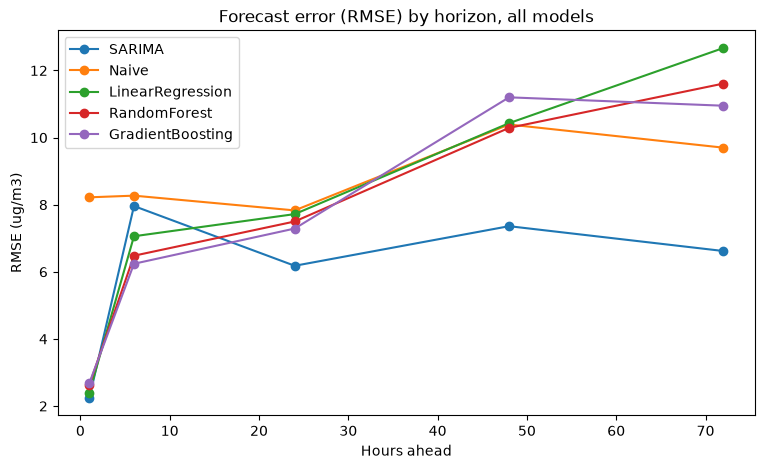

In [39]:
plt.figure(figsize=(9, 5))

for column in compare.columns:
    if column.endswith("_RMSE"):
        name = column.replace("_RMSE", "")
        plt.plot(compare["horizon_hours"], compare[column], marker="o", label=name)

plt.title("Forecast error (RMSE) by horizon, all models")
plt.xlabel("Hours ahead")
plt.ylabel("RMSE (ug/m3)")
plt.legend()
plt.show()

**Interpretation:** (which model has the lowest error at each horizon? does any model beat the naive baseline?
Does the error grow with the horizon? Remember each horizon uses only about 16 starting points.)

### Step 4b: Is the difference real? (Diebold-Mariano test)
One model can have a lower RMSE just by luck. This test asks: are two models' squared errors really different?
- **p-value below 0.05:** the difference is probably real.
- **p-value above 0.05:** we cannot say one is better.

Forecasts from nearby starting points are related, so the test includes a correction for that (Newey-West).

In [40]:
from scipy import stats

def dm_test(errors_a, errors_b, lag):
    # compare squared errors of two models. Negative stat means model A is better.
    d = np.array(errors_a) ** 2 - np.array(errors_b) ** 2
    n = len(d)
    mean_d = d.mean()

    # variance, with a correction for errors that are related to each other
    variance = np.mean((d - mean_d) ** 2)
    for k in range(1, lag + 1):
        weight = 1 - k / (lag + 1)
        covariance = np.mean((d[k:] - mean_d) * (d[:-k] - mean_d))
        variance = variance + 2 * weight * covariance

    if variance <= 0:
        return np.nan, np.nan

    stat = mean_d / np.sqrt(variance / n)
    p_value = 2 * (1 - stats.norm.cdf(abs(stat)))
    return stat, p_value


def verdict(name_a, name_b, stat, p_value):
    if np.isnan(p_value):
        return "could not test"
    if p_value >= 0.05:
        return "no clear difference"
    if stat < 0:
        return name_a + " is better"
    return name_b + " is better"


significance_rows = []

for h in horizons:
    lag = max(0, (h - 1) // origin_step)
    sarima_e = np.array(sarima_errors[h])
    naive_e = np.array(naive_errors[h])

    # SARIMA against the naive baseline
    stat, p_value = dm_test(sarima_e, naive_e, lag)
    significance_rows.append({"horizon_hours": h, "comparison": "SARIMA vs Naive",
                              "p_value": round(p_value, 3), "result": verdict("SARIMA", "Naive", stat, p_value)})

    # each machine learning model against SARIMA
    for name in ["LinearRegression", "RandomForest", "GradientBoosting"]:
        key = name + "_" + str(h)
        if key not in ml_errors:
            continue
        if len(ml_errors[key]) != len(sarima_e):
            print("Different number of starting points for", key, "- skipped")
            continue
        stat, p_value = dm_test(ml_errors[key], sarima_e, lag)
        significance_rows.append({"horizon_hours": h, "comparison": name + " vs SARIMA",
                                  "p_value": round(p_value, 3), "result": verdict(name, "SARIMA", stat, p_value)})

significance_table = pd.DataFrame(significance_rows)
print(significance_table.to_string())
significance_table.to_csv("significance_results.csv", index=False)

    horizon_hours                  comparison  p_value               result
0               1             SARIMA vs Naive    0.000     SARIMA is better
1               1  LinearRegression vs SARIMA    0.590  no clear difference
2               1      RandomForest vs SARIMA    0.248  no clear difference
3               1  GradientBoosting vs SARIMA    0.194  no clear difference
4               6             SARIMA vs Naive    0.599  no clear difference
5               6  LinearRegression vs SARIMA    0.372  no clear difference
6               6      RandomForest vs SARIMA    0.215  no clear difference
7               6  GradientBoosting vs SARIMA    0.096  no clear difference
8              24             SARIMA vs Naive    0.065  no clear difference
9              24  LinearRegression vs SARIMA    0.122  no clear difference
10             24      RandomForest vs SARIMA    0.264  no clear difference
11             24  GradientBoosting vs SARIMA    0.338  no clear difference
12          

**Interpretation:** (at which horizons is SARIMA clearly better than the naive baseline? do the machine learning models beat SARIMA
or is the difference not clear? "no clear difference" is a valid, honest result.)

## Step 5: Which features matter? (+24 hours)

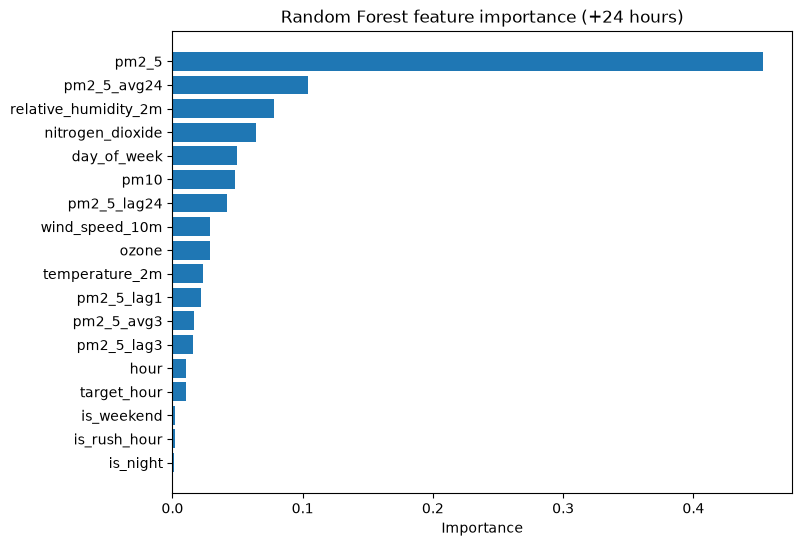

In [41]:
x_train, y_train, x_test, y_test = make_data(24, all_features)

forest_24 = RandomForestRegressor(n_estimators=200, random_state=42)
forest_24.fit(x_train, y_train)

importance = pd.Series(forest_24.feature_importances_, index=x_train.columns)
importance = importance.sort_values()

plt.figure(figsize=(8, 6))
plt.barh(importance.index, importance.values)
plt.title("Random Forest feature importance (+24 hours)")
plt.xlabel("Importance")
plt.show()

**Interpretation:** (which 3 features matter most? are weather features important or is it mostly past PM2.5?)

In [42]:
# Linear Regression numbers (on scaled columns, so sizes can be compared)
mean = x_train.mean()
std = x_train.std().replace(0, 1)
linear_24 = LinearRegression()
linear_24.fit((x_train - mean) / std, y_train)

coefficients = pd.Series(linear_24.coef_, index=x_train.columns).sort_values()
print(coefficients.round(2))

day_of_week            -1.16
pm2_5_avg3             -0.99
relative_humidity_2m   -0.95
pm2_5_lag3             -0.12
temperature_2m         -0.12
hour                   -0.06
target_hour            -0.06
pm2_5_avg24            -0.04
is_night                0.14
is_rush_hour            0.25
pm2_5_lag24             0.48
wind_speed_10m          0.51
pm2_5_lag1              0.58
pm10                    0.78
is_weekend              1.28
ozone                   1.55
nitrogen_dioxide        3.68
pm2_5                   4.76
dtype: float64


**Interpretation:** (positive number = PM2.5 goes up when this goes up; negative = goes down. Is wind negative?)

## Step 6: Sensitivity check (Random Forest, +24 hours)
Do the results change if we remove the weather columns, or train on a shorter window?

In [43]:
sensitivity_rows = []

# all features (normal)
x_train, y_train, x_test, y_test = make_data(24, all_features)
model = RandomForestRegressor(n_estimators=200, random_state=42)
model.fit(x_train, y_train)
rmse, mae = get_errors(y_test, model.predict(x_test))
sensitivity_rows.append({"version": "All features", "RMSE": rmse, "MAE": mae})

# without weather columns
no_weather = []
for name in all_features:
    if name not in weather_features:
        no_weather.append(name)

x_train, y_train, x_test, y_test = make_data(24, no_weather)
model = RandomForestRegressor(n_estimators=200, random_state=42)
model.fit(x_train, y_train)
rmse, mae = get_errors(y_test, model.predict(x_test))
sensitivity_rows.append({"version": "Without weather", "RMSE": rmse, "MAE": mae})

# shorter training window (only the later half of the training period)
x_train, y_train, x_test, y_test = make_data(24, all_features, first_train_row=test_start // 2)
model = RandomForestRegressor(n_estimators=200, random_state=42)
model.fit(x_train, y_train)
rmse, mae = get_errors(y_test, model.predict(x_test))
sensitivity_rows.append({"version": "Shorter training window", "RMSE": rmse, "MAE": mae})

sensitivity_table = pd.DataFrame(sensitivity_rows).round(2)
print(sensitivity_table)
sensitivity_table.to_csv("sensitivity_results.csv", index=False)

                   version  RMSE   MAE
0             All features  7.50  6.29
1          Without weather  7.25  6.15
2  Shorter training window  7.90  6.48


**Interpretation:** (do the results change a lot? what does that say about how stable the model is?)

## Step 7 (optional): "High PM2.5 or not" in 24 hours
This turns the forecast into a yes/no question, so we can use a confusion matrix, precision, recall, F1 and ROC/AUC.
"High" means above the 75th percentile of the training hours (so both classes have enough examples).

In [44]:
high_limit = table["pm2_5"][:test_start].quantile(0.75)
print("High PM2.5 means above:", round(high_limit, 1))

table["high_in_24h"] = 0
table.loc[table["pm2_5"].shift(-24) > high_limit, "high_in_24h"] = 1

columns = all_features + ["target_hour"]
table["target_hour"] = table["hour"]       # +24 hours is the same hour of day

train_rows = list(range(0, test_start - 24))
test_rows = list(range(test_start - 1, len(table) - 24))     # every hour in the test period

x_train = table.loc[train_rows, columns]
y_train = table.loc[train_rows, "high_in_24h"]
x_test = table.loc[test_rows, columns]
y_test = table.loc[test_rows, "high_in_24h"]

classifier = RandomForestClassifier(n_estimators=200, random_state=42)
classifier.fit(x_train, y_train)

answer = classifier.predict(x_test)
chance = classifier.predict_proba(x_test)[:, 1]

print("Confusion matrix (rows = real, columns = predicted):")
print(confusion_matrix(y_test, answer))
print("Precision:", round(precision_score(y_test, answer, zero_division=0), 2))
print("Recall:", round(recall_score(y_test, answer, zero_division=0), 2))
print("F1 score:", round(f1_score(y_test, answer, zero_division=0), 2))

if len(set(y_test)) == 2:
    print("ROC AUC:", round(roc_auc_score(y_test, chance), 2))
else:
    print("ROC AUC needs both classes in the test period.")

High PM2.5 means above: 33.8
Confusion matrix (rows = real, columns = predicted):
[[229  33]
 [ 12  13]]
Precision: 0.28
Recall: 0.52
F1 score: 0.37
ROC AUC: 0.87


**Interpretation:** (how many high hours did we catch? how many false alarms?)

## Step 8: Save the Random Forest (+24 hours) for the dashboard

In [ ]:
x_train, y_train, x_test, y_test = make_data(24, all_features)

final_model = RandomForestRegressor(n_estimators=200, random_state=42)
final_model.fit(x_train, y_train)

saved = {"model": final_model, "features": list(x_train.columns)}

with open("model.pkl", "wb") as file:
    pickle.dump(saved, file)

print("Saved model.pkl")

Saved model.pkl


## Notes for the report
- ML models forecast each horizon directly (a separate model for +1, +6, +24, +48, +72 hours).
- Test starting points are the same as SARIMA's, so the comparison is fair.
- The "high PM2.5" label uses the 75th percentile of training hours, not a health standard.
- Next: Phase 7 (`app.py`) reads `model_comparison.csv` and `model.pkl`.

# Part 4: Checks against real-world data
Our data comes from a model (CAMS), not from sensors. These two checks test how far it can be trusted.
Both are optional: a cell skips itself with a message if its file is missing.

## Check A: compare with a real ground sensor
1. Get hourly PM2.5 readings for Karachi from a real monitor, for the same dates as your data. Options: the OpenAQ website (free account),
   or AirNow / the US Consulate monitor if one is listed for Karachi.
2. Save it as `ground_sensor.csv` in the project folder, with one column for the time and one for PM2.5 (ug/m3).
3. Set the three names below to match your file.

In [ ]:
import os

# ----- change these to match your file -----
sensor_file = "ground_sensor.csv"
sensor_time_column = "time"
sensor_value_column = "pm2_5"
sensor_time_is_utc = True       # OpenAQ files use UTC. Use False if your times are already Karachi time.

In [ ]:
if not os.path.exists(sensor_file):
    print("File not found:", sensor_file, "- skipping Check A.")
else:
    sensor = pd.read_csv(sensor_file)

    # make the times Karachi local time, rounded down to the hour
    if sensor_time_is_utc:
        sensor_time = pd.to_datetime(sensor[sensor_time_column], utc=True)
        sensor_time = sensor_time.dt.tz_convert("Asia/Karachi").dt.tz_localize(None)
    else:
        sensor_time = pd.to_datetime(sensor[sensor_time_column])

    sensor["time"] = sensor_time.dt.floor("h")
    sensor["sensor_pm2_5"] = sensor[sensor_value_column]

    # one value per hour
    sensor = sensor.groupby("time")["sensor_pm2_5"].mean().reset_index()

    # the model data (CAMS) for the same hours
    model_data = pd.read_csv("karachi_aq_history.csv")
    model_data["time"] = pd.to_datetime(model_data["time"])
    model_data = model_data[["time", "pm2_5"]]

    both = pd.merge(model_data, sensor, on="time")
    both = both.dropna()
    print("Hours in common:", len(both))

    if len(both) < 24:
        print("Fewer than 24 hours in common - check the dates and time zone of your file.")
    else:
        difference = both["pm2_5"] - both["sensor_pm2_5"]

        print("Correlation:", round(np.corrcoef(both["pm2_5"], both["sensor_pm2_5"])[0, 1], 2))
        print("Average difference (model minus sensor):", round(difference.mean(), 1), "ug/m3")
        print("RMSE:", round(np.sqrt(np.mean(difference ** 2)), 1), "ug/m3")
        print("MAE:", round(np.mean(np.abs(difference)), 1), "ug/m3")

        plt.figure(figsize=(12, 4))

        plt.subplot(1, 2, 1)
        plt.scatter(both["sensor_pm2_5"], both["pm2_5"], s=5)
        top = max(both["sensor_pm2_5"].max(), both["pm2_5"].max())
        plt.plot([0, top], [0, top], color="red", linestyle="--", label="Perfect match")
        plt.title("Model vs ground sensor")
        plt.xlabel("Sensor PM2.5")
        plt.ylabel("Model PM2.5")
        plt.legend()

        plt.subplot(1, 2, 2)
        plt.plot(both["time"], both["sensor_pm2_5"], label="Sensor")
        plt.plot(both["time"], both["pm2_5"], label="Model")
        plt.title("Over time")
        plt.xlabel("Time")
        plt.legend()

        plt.tight_layout()
        plt.show()

**Interpretation:** (high correlation but a big average difference means the model follows the ups and downs but is too high or too low.
Say clearly how much the CAMS data can be trusted for Karachi.)

## Check B: compare with Open-Meteo's own 24-hour forecast
`collector.py` and `collect_once.py` save Open-Meteo's own forecast for 24 hours ahead into `forecast_log.csv` every hour.
After some days, we can compare, for the same hours: Open-Meteo's forecast, our Random Forest, and the naive baseline.
This check needs several days of logging, so start the collector early.

In [ ]:
import pickle

log_file = "forecast_log.csv"

if not os.path.exists(log_file):
    print("File not found:", log_file, "- start collector.py (or collect_once.py) and come back after a few days.")
else:
    log = pd.read_csv(log_file)
    log["made_at"] = pd.to_datetime(log["made_at"])
    log["target_time"] = pd.to_datetime(log["target_time"])

    data = pd.read_csv("clean_data.csv")
    data["time"] = pd.to_datetime(data["time"])
    data["target_hour"] = data["hour"]

    with open("model.pkl", "rb") as file:
        saved = pickle.load(file)

    check_rows = []
    for index in range(len(log)):
        made_at = log["made_at"][index]
        target_time = log["target_time"][index]

        now_row = data[data["time"] == made_at]
        target_row = data[data["time"] == target_time]

        # only use hours where we know both the starting row and the real result
        if len(now_row) == 1 and len(target_row) == 1:
            real = target_row["pm2_5"].values[0]
            forest_guess = saved["model"].predict(now_row[saved["features"]])[0]
            naive_guess = now_row["pm2_5"].values[0]
            openmeteo_guess = log["openmeteo_pm2_5_forecast"][index]

            check_rows.append({"real": real, "openmeteo": openmeteo_guess,
                               "random_forest": forest_guess, "naive": naive_guess})

    check = pd.DataFrame(check_rows).dropna()
    print("Forecasts we can check:", len(check))

    if len(check) < 24:
        print("Fewer than 24 forecasts so far - collect for a few more days.")
    else:
        result_rows = []
        for name in ["openmeteo", "random_forest", "naive"]:
            errors = check["real"] - check[name]
            result_rows.append({"forecast": name,
                                "RMSE": round(np.sqrt(np.mean(errors ** 2)), 2),
                                "MAE": round(np.mean(np.abs(errors)), 2)})
        print(pd.DataFrame(result_rows))

**Interpretation:** (does our Random Forest come close to Open-Meteo's forecast? if it is worse, that is fine: their forecast comes from a much bigger model.
Note that the Random Forest was trained earlier, and the "real" values come from the same CAMS source.)

## Notes for the report (Part 4)
- Check A shows whether CAMS data matches a real monitor in Karachi. It is the biggest limitation of the project, so report the result honestly.
- Check B compares live 24-hour forecasts. It only has as many rows as you collected.